# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [71]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [72]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [73]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


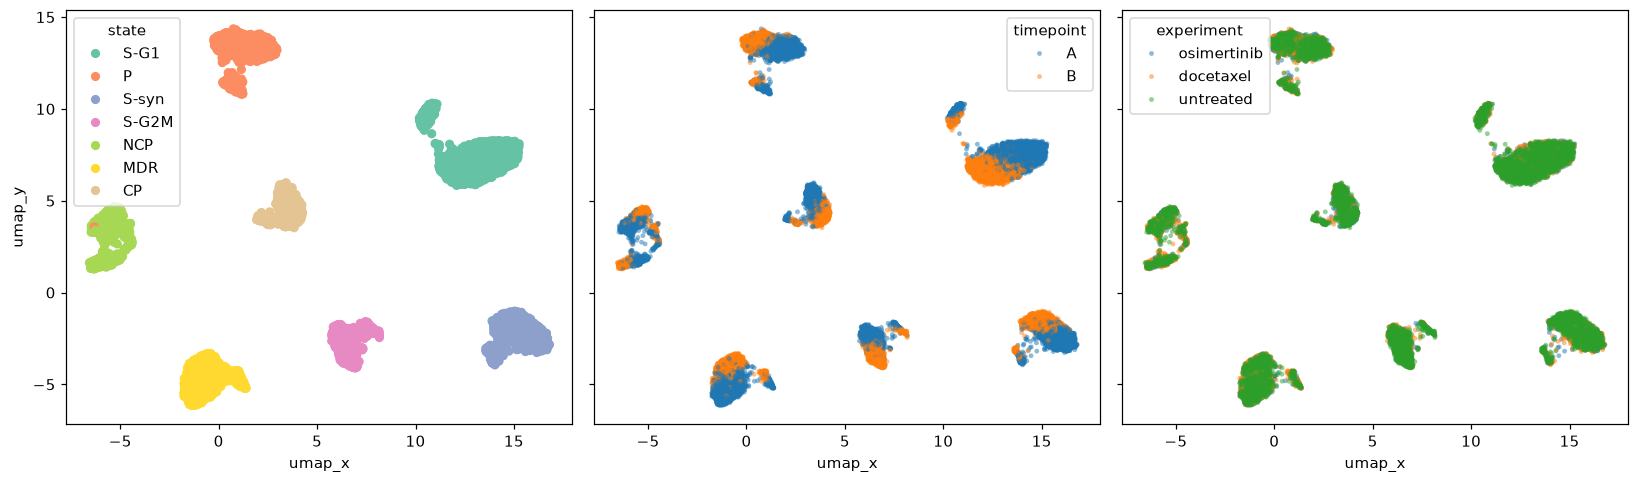

In [74]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [75]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [76]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [77]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [78]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [79]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [80]:



STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

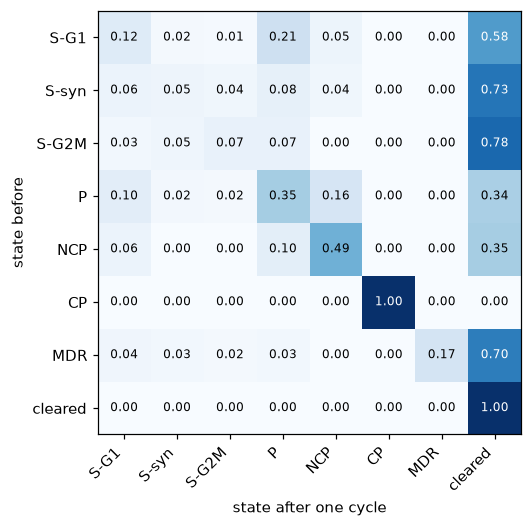

In [81]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?


</div>



<font color = burntorange>


CP is an absorbing state under osimertinib. The probability of CP transitioning to CP after a round of osimertinib is 1.  This probability transition means CP was completely unresponsive to the drug treatment. As a result, any tumors that have CP cells cannot be treated entirely by osimertinib.


## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

<font color = "burntorange">

Osimertinib appeared to eliminate S-syn and SG2-M almost entirely (Cells that transition almost entirely to cleared were mostly eliminated by the drug.  Osimertinib does not appear to affect CP at all; the probability of it transitioning back to itself after a round of osimertinib is 1.

Cells that transitioned back into themselves partially were not completely responsive to the drug treatment; some of these cells transitioned to cleared meaning that they were partially cleared by the drug.  These cells were P, NCP, and MDR. 


Some of the cells transitioned into other cells. This transition suggests that some of these cells were turning into other cells. Both P and NCP cells transitioned into each other, suggesting that these cells changed into each other. S-G1 transitioned partially into P suggesting that part of the S-G1 cells turned in to P cells.


If these cells are responsive to osimertinib, multiple rounds should then continue to decrease the number of those cells eventually into entirely cleared. CP is the only cell that remains completely unaffected by the drug, but also from the transition matrix, we can see that no other cells can transition into CP in order to escape being cleared. 

In [82]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [83]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [84]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

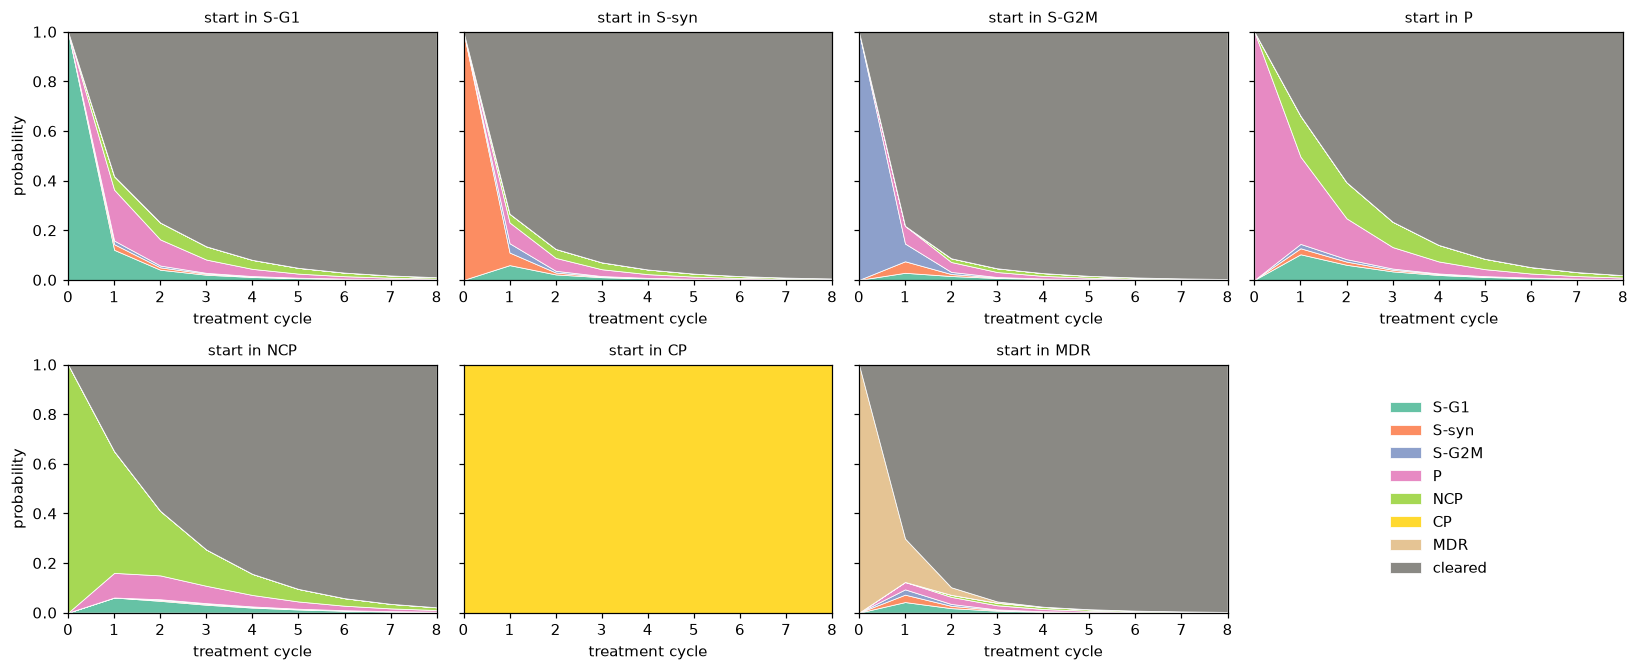

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [85]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



<font color = "burntorange">

<em> Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive? </em>

Osimertinib appears to be able to completely eliminate S-syn, S-G2M, and MDR.  P, NCP, and SG-1 appear to be a bit more sticky due to their ability to transition into each other, but their levels are decreasing, suggesting that with repeated rounds, they can be eliminated.  CP remains unaffected, meaning it never transitions to a cleared state or any other state that could be cleared.


<em> Of the states that can be cleared, which tumor lasts the longest? </em>

Of the states that can be cleared, NCP lasts the longest, followed closely by P and SG-1. NCP likely lasts the longest because it has the highest self transition in the transition matrix, suggesting that it has a longer survival rate and can transition back and forth to P (it is more sticky in other states). 

<em> Which starting state sticks around for the most cycles of drug? </em>

CP sticks around for all cycles of the drug.  It stays within its same state.  Also, no cells transition into or out of CP.

<em>Which starting state results in the highest proportion of alive cells after three cycles?</em>

Again, CP sticks around with the highest proportion of alive cells after 3 cycles.  It is not affected by the drug and stays in its same state after rounds of treatment.  It does not transition out of its state, and no other cells transition in or out of its state.

Of all the cells that can be cleared, NCP has the highest number of cells still alive after 3 cycles.  Presumably, because it transitions with a high probability back to itself (.49) and transition to P, takes more transitions to entirely transition into cleared.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

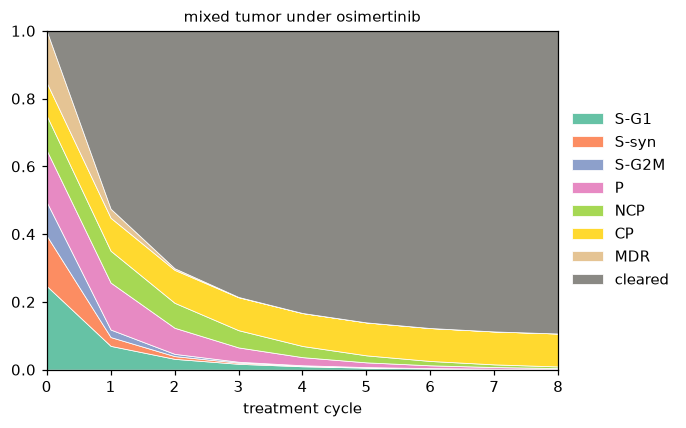

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


In [86]:
# Your code here

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_mix = evolve(pi_mix, P_hat, N_CYCLES)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix, ax, "mixed tumor under osimertinib")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

traj_mix_df = pd.DataFrame(traj_mix, columns=OUTCOMES).round(3)
traj_mix_df


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

<font color = "burntorange">

<em>
Which state ends up dominating the remaining cluster?
</em>

Outside of the cleared state, the CP cells state ends up dominating the remaining cluster.  CP cells start as around 10% of the cells at the start, and at the end, they are almost 91% of the remaining cluster.  However, we know from the transition matrix that they are not transitioning to other cells, they are merely not transitioning to cleared and only to themselves.  They are not receptive at all to the treatment.

<em>
Will these states ever be cleared?
</em>

The CP cells do not ever transition to another state outside of itself, not even cleared. They will never be cleared.

<em>
How does the long-run endpoint relate to the transition matrix?
</em>

The long-run endpoint relates to the transition matrix in several ways.  First, and most conspicuously, the CP cells in the transition matrix are an absorpting state in that they only transition to themselves after treatment with osimertinib (100% of the time). As a result, the long-run endpoint still has all of the CP cells that it started with at the beginning of the treatment.  

The NCP and P cells persist longer than the other cells before becoming mostly absorbed by cleared by the long run endpoint.  NCP and P cells both have high probabilities of transitions to themselves (.49 and .35, respectively) in the transition matrix, and they also transition back and forth to each other (P -> NCP: .16, NCP -> P:.10).  Hence, these two cells are the stickiest in that they have other avenues for transition and at higher probabilities than the other cells, and hence, they take more cycles to transition completely to cleared.  

Overall, the NCP and P cells will in all likelihood eventually transition to cleared to be absorbed, whereas CP cells will not transition anywhere except to themselves. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [87]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position


doce = cells[cells["experiment"] == "docetaxel"]
drugh = cells[cells["experiment"] == "untreated"]

doce_at_A = doce[doce.timepoint == "A"][["lineage_tag", "state"]]
doce_at_B = doce[doce.timepoint == "B"][["lineage_tag", "state"]]

drugh_at_A = drugh[drugh.timepoint == "A"][["lineage_tag", "state"]]
drugh_at_B = drugh[drugh.timepoint == "B"][["lineage_tag", "state"]]


pairs_doce = pd.merge(doce_at_A, doce_at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_doce["state_B"] = pairs_doce["state_B"].fillna("cleared")

pairs_untreated = pd.merge(drugh_at_A, drugh_at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_untreated["state_B"] = pairs_untreated["state_B"].fillna("cleared")

STATES = [s for s in STATE_ORDER if s in set(cells["state"])]  
OUTCOMES = STATES + ["cleared"]

counts_doce = (pd.crosstab(pairs_doce.state_A, pairs_doce.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = counts_doce.div(counts_doce.sum(axis=1), axis=0)

counts_untreated = (pd.crosstab(pairs_untreated.state_A, pairs_untreated.state_B)
                     .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_untreated = counts_untreated.div(counts_untreated .sum(axis=1), axis=0)

#add a cleared row that stays cleared with p = 1
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})
P_untreated.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_untreated.columns})


P_osi = P_hat.to_numpy()

P_doc_df = P_doc                    
P_holiday_df = P_untreated

P_doc = P_doc_df.to_numpy()         
P_holiday = P_holiday_df.to_numpy()

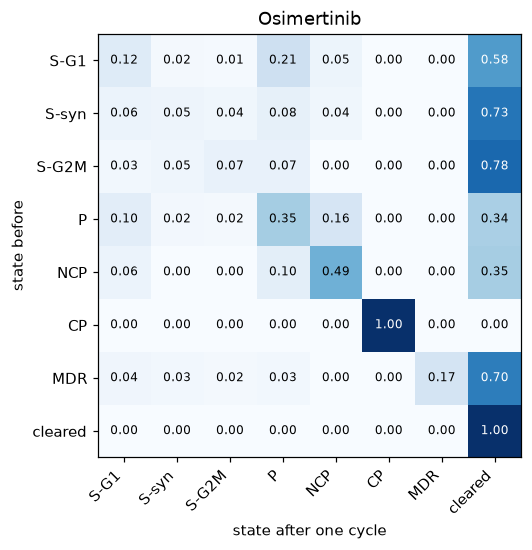

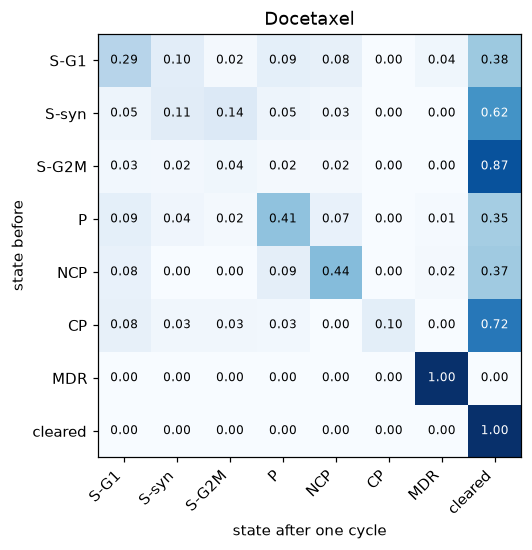

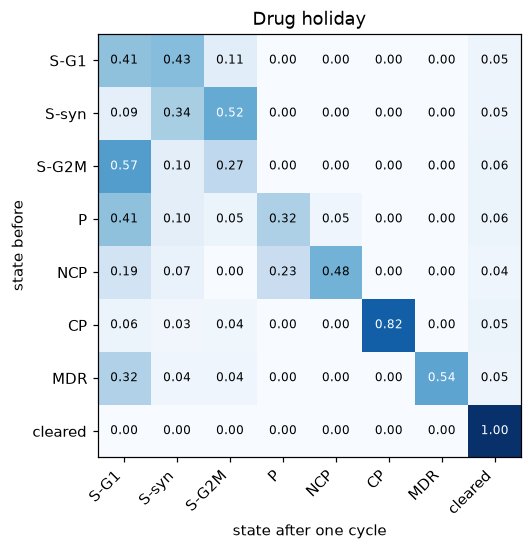

In [88]:
#Plot the transition matrices for docetaxel and the drug holiday.
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat, title="Osimertinib")
show_matrix(P_doc_df, title="Docetaxel")
show_matrix(P_holiday_df, title="Drug holiday")

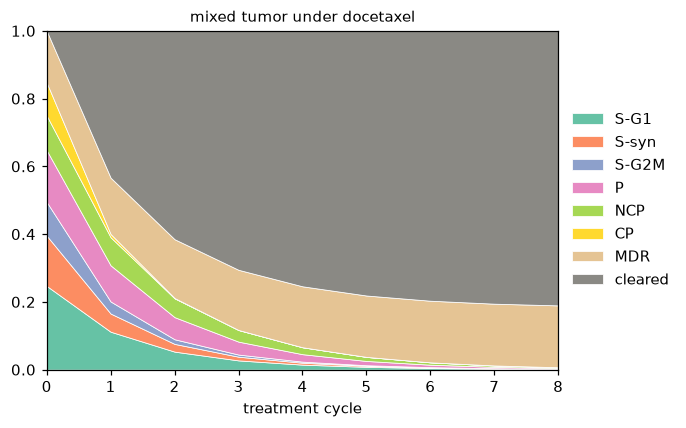

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [89]:
# Simulate the evolution of pi_mix under docetaxel 

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_mix_doc = evolve(pi_mix, P_doc_df, N_CYCLES)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix_doc, ax, "mixed tumor under docetaxel")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()



pd.DataFrame(traj_mix_doc, columns=OUTCOMES).round(3)

<font color = "burntorange">
<em>
<b>1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states? </b>
</em>

<b> Drug holiday </b>

The transition matrix under drug holiday does not have any strong absorbing states except for cleared  (cells that are cleared do not transition into anything other than cleared).  

a)
Many of the cells transition the strongly back into themselves, suggesting that the cancer cells are somewhat likely to stay in their same state, see the main diagonal in the transition matrix.  

b)
A small percentage of the cells transition into clear, e.g., die naturally. 

c) The S-G1 cell transition most of the time into the S-syn cell instead of itself (.43), meaning that it will change into another cell most of the time.  The S-syn cell follows a similar trend in that it transitions into S-G2M most of the time (.52).  Most of the cells have high transition probabilities into the S-G1 cell (except S-syn and CP cells), suggesting that many cells become S-G1 cells in the absence of treatment.  From S-G1, many of the cells transition back to S-syn where they cycle back to S-G2M.  Hence, these transitions appear to create a cycle of the changing of the cancer cells over time.  

d) Osimertinib tends to stop certain cancer cells from transitioning to other cancer cell states.The CP cells transition to CP cells around 82% of the time; however, in the absence of treatment, CP is no longer an absorbing state as some of these cells transition in very small rates to other cells.  Presumably, treatment may not influence the presence of CP cell, but treatment also stops these cells from transitioning to another type of cell. The same appears to be the case P and NCP.  Without osmertinib, they are more likely to transition into S-G1 (P:.10 to .41; NCP: .06 to .19), and transition goes more towards P than NCP (NCP to P: .10 to .23 and P to NCP: .16 to .05). 


<b> Docetaxel </b>



a) Cleared:

May of the cancer cells transition into cleared at high probabilities except MDR.

b)
Transition prevention

With docetaxel, many of the cells including CP this time transition into a cleared state, except MDR.  MDR becomes an absorbing state in that it only transitions into itself 100% of the time (not into S-G1 as it does on drug holiday).The probability at which other cancer cells transition into S-G1 cells decreases, so presumably, the drug prevents that transition in comparison to drug holiday. 

Unlike seen with osimertinib and CP, with docetaxel and MDR, some other cancer cells can transition into MDR. So some of the other types of cancer cells are able to escape clearing by transitioning to MDR, albeit at very small rates (S-G1: .04, P: .01, NCP: .02). With osimertinib, none of the other cancer cells were able to transition to CP.

This docetaxel also appears to prevent the transitioning of P to NCP seen in osimertini.  P and NCP transition to one another a bit less than in osimertinib.



<em>
<b>2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens? </b>
</em>

Most of the cells transition into cleared (die) except MDR, which makes up 96.32% of the surviving cells. As shown in the transition matrix, MDR becomes an absorbing state.  It only transitions to itself; however, some cells are able to transition into MDR, so it is not completely isolated. Indeed, the percentage of overall cells in MDR increases from treatment start to treatment cycle 8: .153 to .183.




## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

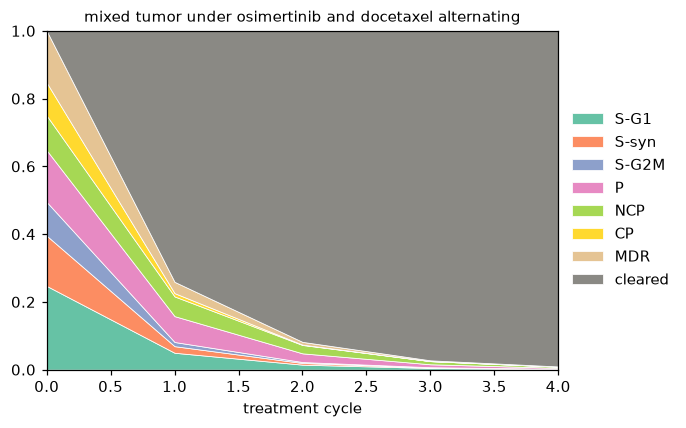

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.050,0.019,0.012,0.076,0.058,0.010,0.033,0.741
2,0.015,0.005,0.003,0.026,0.025,0.001,0.008,0.918
3,0.005,0.002,0.001,0.009,0.009,0.000,0.002,0.973
4,0.002,0.001,0.000,0.003,0.003,0.000,0.001,0.991


In [90]:
## Add code here

# Simulate the evolution of pi_mix under osimertinib and docetaxel alternating starting with osimertinib

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_alt_OD = evolve(pi_mix, P_osi @ P_doc, 4)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_alt_OD, ax, "mixed tumor under osimertinib and docetaxel alternating")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()



pd.DataFrame(traj_alt_OD, columns=OUTCOMES).round(3)

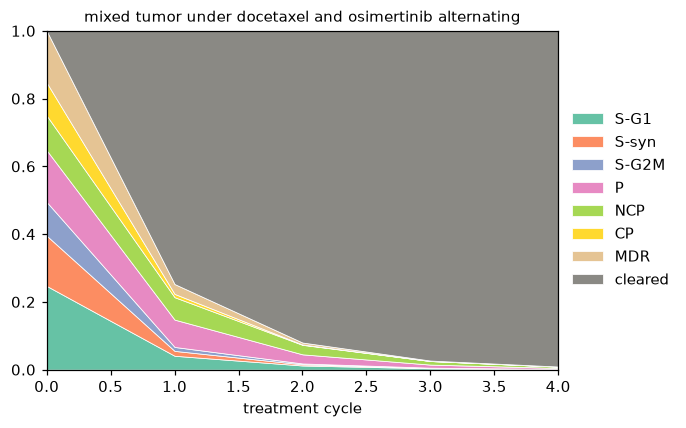

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.041,0.014,0.012,0.081,0.066,0.010,0.029,0.747
2,0.012,0.003,0.003,0.027,0.028,0.001,0.006,0.920
3,0.004,0.001,0.001,0.009,0.011,0.000,0.001,0.973
4,0.001,0.000,0.000,0.003,0.004,0.000,0.000,0.991


In [91]:
## Add code here

# Simulate the evolution of pi_mix under alternations of docetaxel and osimertinib starting with doce

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_alt_OD = evolve(pi_mix, P_doc @ P_osi, 4)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_alt_OD, ax, "mixed tumor under docetaxel and osimertinib alternating")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()



pd.DataFrame(traj_alt_OD, columns=OUTCOMES).round(3)

<font color = "burntorange">
<em><b>
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule. 
 - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.</em></b>

The alternating drugs were much more successful at clearing the overall percentage of cell.  Osi first and doce first both cleared around 99.1% of the cancer cells, which just osi cleared 89.3% and just doce cleared 81%.   

Osi alone eliminated most of the other cells at similar rates as alternation except for CP, which persisted in 9.7% of the tumor throughout the treatment. Doce alone cleared almost all other cell types to similar rate as alternation except for MDR which not only persisted but increased in its percentage (from 15.3% to 18.3%) as other cells likely transitioned to MDR to escape clearing. 

By combining both treatments, we were able to clear almost completely the cell types that were resistant to one treatment (CP was resistant to osi, and MDR was doce). However, we feel it important to note that alternating treatments did not clear cancer cells completely.  Around 1% of cancer cells remained and those types that remained differed depending on the order of alternation.  We address this point in more detail below. 


Both alternating cycles appear to clear almost all cancer cells (osi first: .991, doce first: .991).   For osi first, S-G1 (.2%), Syn(.1%), P (.3%), NCP (.3%) and MDR (.1%) had a small amount of cells left after the final cycle.  All of these cells are the stickier cells that had several transition states aside from cleared or were resistant to one of the drugs.  

For doce first rounds, these rounds also had a small amount of cells left after the final cycle but less variation in the types of cells that stuck around (SG1:.1%; P: .3%; NCP: .4%).


<em><b>2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?</em></b>

Overall, in terms of the percentage of cells left, it does not appear to matter which drug we start with first.  However, if we look at the variation in the type of cells that we have left, it does matter which drug we start with first.  Starting with osi, we have more cells types stick around but in smaller numbers. For starting with doce, we appear to have less cell types but of the same overall percentage. Put simply, both rotation had similar amounts of clearing of overall cells.  The osi first had more cell types remaining but in smaller amounts than doce first.


<b><em>3.  In what situation would a drug holiday help clear the tumor? </b></em>

A drug holiday can help cancer cells that are persistant (sticky) or resistant to a drug transition into a state in which the drugs are more effective.

Both osi and doce first alternating treatments had most of their remaining cells being type P and NCP.  Both doce and osi reduce the tranditioning of P and NCP cells to S-G1 states. During a drug holiday, P and NCP cells transition at larger rates to S-G1 states (NCP: .19; P: .41), and S-G1 does not tend to transition into other cell types except S-syn and S-G2.  Both doce and osi combined tend to deal with S-G1 cells quite effectively. Consequently, a drug holiday may aid in moving more cells from sticky regions like P and NCP into less sticky states like S-G1.   

Additionally, for cells such as CP which is resistant to osi and MDR which is resistant to doce, they are both stopped from transitioning to other cell types when being treated by drugs to which they are resistant.  A drug holiday allows CP cells to transition to S-type cells (though at low rates) and MDR cells to transition to S-G1 cells (at 32%).  

<b><em>4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning. </b></em>

In [92]:
equal_mix = np.array([1/7] * 7 + [0])
alt2 = np.linalg.matrix_power(P_osi @ P_doc, 2)    
pair_with_holidays = P_osi @ P_holiday @ P_doc @ P_holiday
pair_with_holidays_DO = P_doc @ P_holiday @ P_osi @ P_holiday

high_ncp = np.array([0.10, 0.10, 0.10, 0.10, 0.40, 0.10, 0.10, 0.0])
#                   S-G1  S-syn S-G2M  P    NCP   CP    MDR  cleared
assert np.isclose(high_ncp.sum(), 1)

high_p = np.array([0.10, 0.10, 0.10, 0.40, 0.10, 0.10, 0.10, 0.0])
#                   S-G1  S-syn S-G2M  P    NCP   CP    MDR  cleared

schedules = {
    "osi x8":      np.linalg.matrix_power(P_osi, 8),
    "doc x8":      np.linalg.matrix_power(P_doc, 8),
    "alt O->D x8": np.linalg.matrix_power(P_osi @ P_doc, 4),
    "alt D->O x8": np.linalg.matrix_power(P_doc @ P_osi, 4),
    "holiday, then alt O->D x8": P_holiday @ np.linalg.matrix_power(P_osi @ P_doc, 4),
    "alt O->D x8, then holiday": np.linalg.matrix_power(P_osi @ P_doc, 4) @ P_holiday,
    "O, D, holiday (x4)":        np.linalg.matrix_power(P_osi @ P_doc @ P_holiday, 4),
    "alt2 between hold": alt2 @ P_holiday @ alt2,
    "O,H,D,H... (no final H)": np.linalg.matrix_power(pair_with_holidays, 3) @ P_osi @ P_holiday @ P_doc,
    "D,H,O,H... (no final H)": np.linalg.matrix_power(pair_with_holidays_DO, 3) @ P_doc @ P_holiday @ P_osi,
    "O,H,D,H... (no final H) 2": np.linalg.matrix_power(pair_with_holidays, 2) @ P_osi @ P_holiday @ P_doc,
    "D,H,O,H... (no final H) 2": np.linalg.matrix_power(pair_with_holidays_DO, 2) @ P_doc @ P_holiday @ P_osi
}
starts = {
    "all CP":  basis("CP", P_hat),
    "all MDR": basis("MDR", P_hat),
    "all P":  basis("P", P_hat),
    "all NCP": basis("NCP", P_hat),
    "mix":     pi_mix,
    "equalmix": equal_mix,
    "high NCP": high_ncp,
    "high P": high_p,
    
}

table = pd.DataFrame({s_name: {sch_name: (start @ M)[-1]          # fraction cleared
                               for sch_name, M in schedules.items()}
                      for s_name, start in starts.items()})
table.round(3)

,all CP,all MDR,all P,all NCP,mix,equalmix,high NCP,high P
osi x8,0.000,0.997,0.981,0.978,0.893,0.848,0.887,0.888
doc x8,0.990,0.000,0.945,0.932,0.810,0.825,0.857,0.861
alt O->D x8,0.994,0.995,0.983,0.981,0.991,0.991,0.988,0.988
alt D->O x8,0.996,0.993,0.985,0.983,0.991,0.991,0.989,0.989
"holiday, then alt O->D x8",0.994,0.994,0.989,0.985,0.992,0.992,0.990,0.991
"alt O->D x8, then holiday",0.994,0.995,0.984,0.982,0.991,0.991,0.988,0.989
"O, D, holiday (x4)",0.997,0.997,0.993,0.992,0.996,0.996,0.995,0.995
alt2 between hold,0.995,0.996,0.987,0.986,0.993,0.993,0.991,0.991
"O,H,D,H... (no final H)",0.998,0.999,0.997,0.997,0.998,0.998,0.998,0.998
"D,H,O,H... (no final H)",0.999,0.998,0.998,0.997,0.998,0.998,0.998,0.998


<font color = "burntorange">

<em><b>Starting mixes</em></b>

For different starting rates, I added an equal mix to assess a general purpose tumor giving each cell an equal stating chance, all P, all NCP, a high NCP mix (40% NCP and equal elsewhere), and a high P mix (40% P and equal elsewhere).  NCP and P are the sticky types of cancer cells, and I wanted to test to make sure they could be eliminated in tumors with high starting amounts of those cells. MDR, CP, and mix were already included, and the mix is the proportion of cancer cells in the dataset, reflecting the distribution in actual cases.

<em><b>Treatment cycles</em></b>

I tried various arrangements of treatment cycles.  I did not want to go above 8 cycles of drugs, but I considered holidays as a break from treatment even though it made the overall treatment longer, e.g. spaced out.  I felt that administering more holidays would not be as detrimental to patient health at more rounds of actual drug treatment (unless it allowed the tumor to grow unchecked which is discussed later in the lab, but for here, I discount that as that was not mentioned as a concern in the instructions).

<b><em>Alternating a holiday within rounds </em></b> 

<em> ODHx4 / DOHx4 </em>

Based on the previous questions, it appeared that holiday cycles were important for moving persistent cells from sticky states. First,  I tried adding in a holiday after both treatments and cycling four times (O,D,H x 4). I did the same treatment again but starting with doce rather than osi. In these treatments, participants got the same cycles drugs as the alternating cycles in question 4 (above); the only thing that varied was when they received the drugs (after a holiday). I found that this treatment was more effective than alternating between drugs cycles without holidays for all starting mixtures (for the mix: .996 versus .991, for the high NCP and P: .995 versus .989). From these results, I surmised that the holidays allowed cells to transition to states that were more susceptible to treatment. 

Because of the success of these results, I thought that perhaps a holiday after every drug treatment would be even more effective, so I tried that schedule.

<em> OHDHx4 / DHOHx4 </em>

The schedule was my most successful treatment, which was four blocks with each block consisting of each drug cycle with a holiday inbetween each drug cycle (OHDH *4 and DHOH *4 but I removed the final holiday in both).  This treatment takes almost twice as long (15 (last h removed) versus 8 cycles), but much of the treatment is holidays. This treatment outperformed the previous holiday treatment on all starting mixes (for the mix: .999-8 versus .996, for the high NCP and P: .998 versus .995). 

Again, patients were administered that same amount of drugs as in the alternating drugs schedule, just with gaps in between administration.   

The only limitation with this treatment schedule is that it is much longer. I would argue that the drug holidays that prolong this schedule do not consist of exposing patients to more drugs that could have health altering side effects.  I do not know if the holidays have adverse side effects or prevent other types of treatments from beginning.  

As a result, to see if I could shorten the length of the treatment schedule, I decided to test a treatment schedule using the same type of blocks, but just 3 repetitions of the blocks.  


<em> OHDHx3 / DHOHx3: Less drugs with more holidays </em> 

For this treatment, I merely reduced the number of blocks.  By doing this reduction, patients received 3/4 of the amount of osi and doce after 11 cycles of treatment.  This treatment schedule did remarkably well considering that patients received <b>three quarters </b> of the amount of drugs that they received in the other treatments. The treatment did just as well as the alternating treatments in our mix from our data (.991-.992 versus .991) and our equal mix (.991-2 versus .991). In fact, this treatment did just as well as alternating drug treatments with a quarter less of the amount of drug treatments.

This treatment does not perform as well as our four block treatment OHDHx4 treatment, but it is an option if shorter treatment is necessary or if an individual has severe adverse side effects from the drugs.  Additionally, this treatment outcome highlights the importance of intermittent drug holidays to transition sticky, persistent cells into drug sensitive cells. Indeed, this result shows that drug holidays certainly important to outcomes or possibly just as important than the drug cycles themselves.



<em> Best choice </em>
The only reason I would choose the 4 block schedule over the 3 block schedule is that it has the best outcomes while administering the same amount of drugs as the other treatment schedules.  Of course, the treatment schedule is longer, but it does not entail administering more drugs, merely prolongs the treatment. This treatment schedule has better outcomes across all of the sample compositions and meaningfully better outcomes in many samples.  


<em> Trends worth noting </em>
For all treatment schedules, starting the treatment with doce works slightly better for tumors with all CP cells than with all MDR cells which responds better to starting with os.  This finding parallels our treatment results in Question 3. Hence, drug order should be considered prior to treatment.

Similarly, with all treatment schedules, starting the treatment with doce appears to do a bit better with all P, all NCP, high NCP mix, and high P mix.  Doce seems to do a better job initally removing or restricting the movement the P cells to NCP from the outset than osi (from our transition tables) they have a greater ability to be cleared in the next treatment if not already cleared.  Although these treatment differences are small in terms of starting drug order, they are consistent across treatment schedule and P/NCP mixes, so they are worth considering.



<em><b> Final Prescription</em></b>

<em>General recommendations:</em>

Firstly, I would recommend that administration order within treatment blocks be determined based on the ratio of MDR versus CP cells.  If the tumor has more CP cells, then each treatment block should begin with doce.  

Secondly, if the tumour has a high proportion of P cells, treatment blocks should start with doce rather than osi.


<em> Treatment recommendations </em>

Choose drug administration cycle order within a block depending on the cell type percentage.  Administer osimertinib and docetaxel with drug holidays after each cycle of the drug within the block (OHDH or DHOH x4) The block is administered 4 times in succession.

If patients have a time shortage or severe side effects to cancer drugs, administer osimertinib and docetaxel with drug holidays after each cycle of the drug within the block (OHDH or DHOH x3).  Each block is administered 3 times in succession.









## 6 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [93]:
rng = np.random.default_rng(100)

In [94]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [95]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

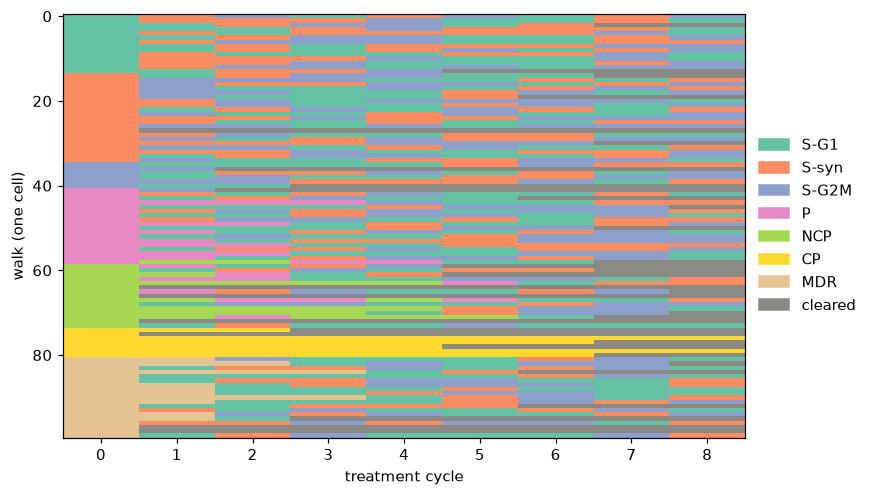

In [96]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [97]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

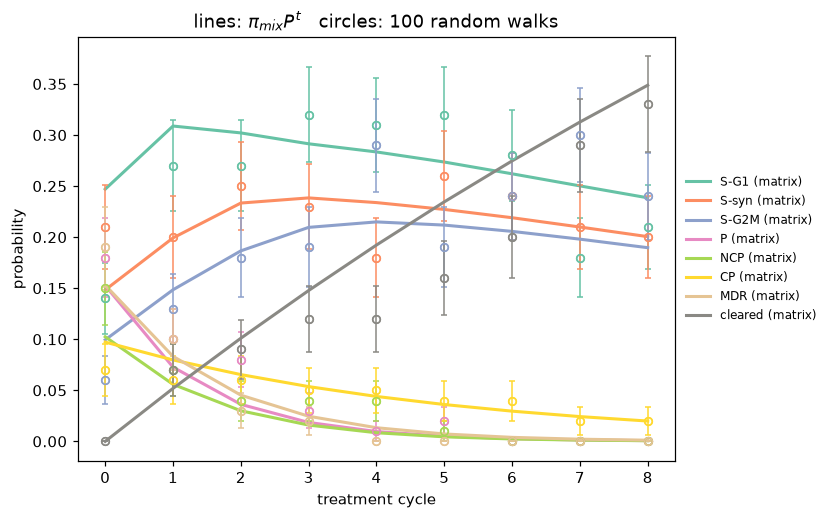

In [98]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

<font color= "burntorange" >

The walks start to more resemble the data from our transition matrix following an increase in the number of walks.  

The lines are the probabilities derived from our our tumor mix (in our data set) over eight drug holiday cycles as determined from our transition matrices. The circles are the proportion of walks that are in a given state at that point in the treatment cycle. 

After increasing the number of walks by a factor of 100, we can see that the circles tend to follow the lines more closely.  


The transition at each state in the walk is randomly drawn from the CDF of a cell's transitions in that state.  Consequently, the walk is more likely to transition into the most probable states in the CDF.  However, some cells will randomly draw a less frequent state in the CDF and transition there instead. As a result, the walks will vary as a function of the probability distributions of the state they are in at each cycle of the walk.  With 100 walks, the walks that transition to less probable states cause variability in the average walks and cause deviation from the lines drawn from our transition matrix. By increasing the number of walks, we decrease the variability in the average walks and walks appear to transition more similarly to the probabilities in our matrix.

 
We see this same trend in the error bars that decrease from 100 to 10,000 walks. The error bars represent the standard error of the mean of the walk proportions (how the mean of the proportion of walks that would arrive in a given state a point in the cycle may vary across resampling).



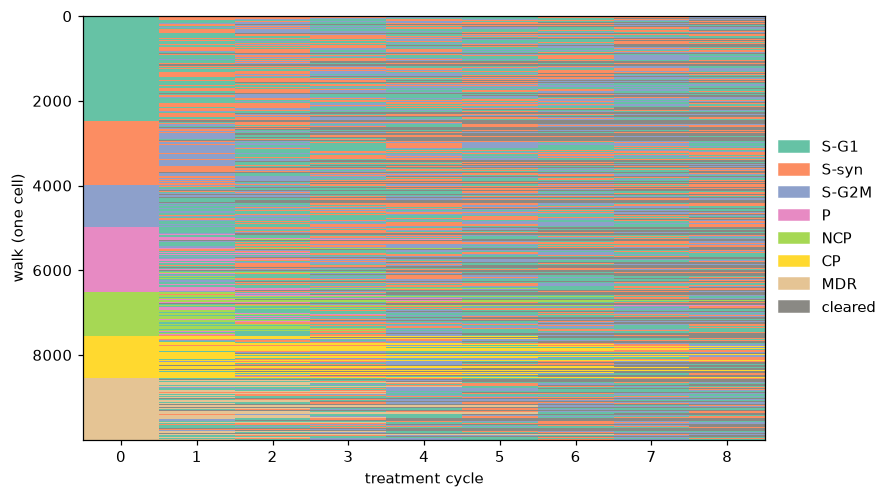

In [99]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [100]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

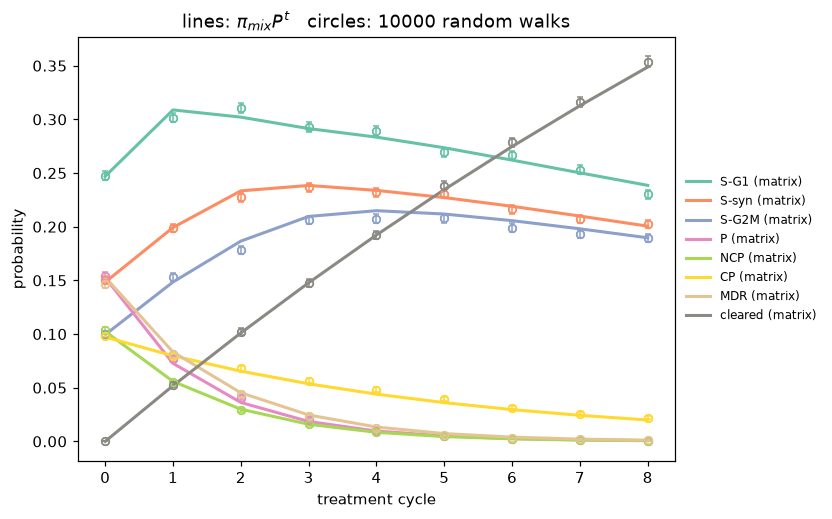

In [101]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

## 7. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [102]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

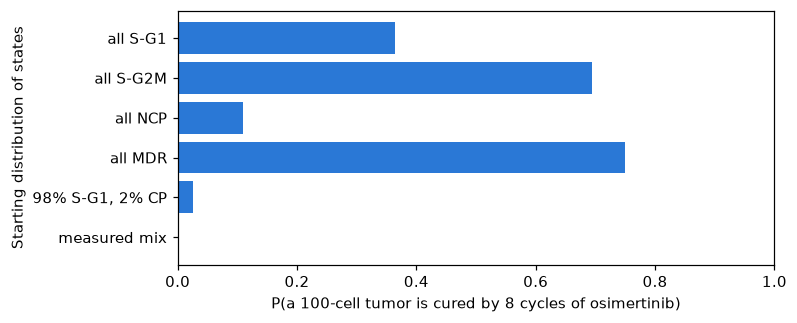

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [103]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

<font color = "burntorange">

The results look very different when treating with 8 cycles of doce. The only starting point that clears completely at any decent probable degree (.545) is when the tumor starts with all SG2M cells.  There is a very small probability that the tumor will clear starting with 98% S-G1 and 2% CP, and there is no probability that the tumor will clear with any of the other mixtures.   

From my prescription earlier, it appears that the standard associating with curing the tumor is higher than I had anticipated.  After 8 cycles, we saw above that doc kills 81% of the mix, but that is quite far from a cure.

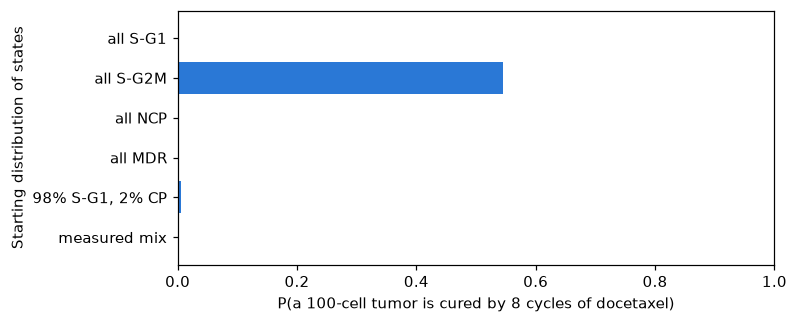

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.805,0.863
all S-G2M,0.545,0.610,0.631
all NCP,0.000,6.690,0.800
all MDR,0.000,100.000,1.000
"98% S-G1, 2% CP",0.005,6.985,0.866
measured mix,0.000,18.955,0.964


In [104]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel
scenarios = {
    "all S-G1":       basis("S-G1", P_doc_df),
    "all S-G2M":      basis("S-G2M", P_doc_df),
    "all NCP":         basis("NCP", P_doc_df),
    "all MDR":        basis("MDR", P_doc_df),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_doc_df) + 0.02 * basis("CP", P_doc_df),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [115]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

pr_rng = np.random.default_rng(5030)
persister_states = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def simulate_pr_tumor(schedule, rng, n_cells=1000):
    # Each row is one cell. Column 0 is its state before treatment.
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(len(OUTCOMES), size=n_cells, p=pi_mix)

    streak = np.isin(paths[:, 0], persister_states).astype(int)
    pr_state = len(OUTCOMES)  # New absorbing state for permanent resistance

    for cycle, matrix in enumerate(schedule, start=1):
        previous = paths[:, cycle - 1]
        current = previous.copy()  # Cells already in PR stay there.

        for state, probabilities in enumerate(matrix):
            group = previous == state
            current[group] = rng.choice(
                len(OUTCOMES), size=group.sum(), p=probabilities
            )

        in_persister = np.isin(current, persister_states)
        streak = np.where(in_persister, streak + 1, 0)
        current[streak >= 3] = pr_state
        paths[:, cycle] = current

    return paths

pr_schedules = {
    "Osimertinib alone": [P_osi] * 8,
    "Docetaxel alone": [P_doc] * 8,
    "Alternating O then D": [P_osi, P_doc] * 4,
    "One holiday, then 7 D": [P_holiday] + [P_doc] * 7,

}

pr_state = len(OUTCOMES)
percent_above = {}
for name, schedule in pr_schedules.items():
    # One row per tumor, one column per completed cycle.
    pr_counts = np.array([
        (simulate_pr_tumor(schedule, pr_rng)[:, 1:] == pr_state).sum(axis=0)
        for _ in range(100)
    ])

    # More than 10% of 1,000 cells means at least 101 PR cells.
    percent_above[name] = pd.Series(
    100 * (pr_counts > 100).mean(axis=0),
    index=range(1, len(schedule) + 1)
)

    if name == "Osimertinib alone":
        final_percent = 100 * pr_counts[:, -1] / 1000
        mean_pr = final_percent.mean()
        sem_pr = final_percent.std(ddof=1) / np.sqrt(len(final_percent))

# 95% t interval for the mean across 100 independent tumors (99 df).
low = mean_pr - 1.984 * sem_pr
high = mean_pr + 1.984 * sem_pr
print(f"Osimertinib after 8 cycles: mean PR = {mean_pr:.2f}%")
print(f"SEM = {sem_pr:.2f} percentage points; 95% CI = [{low:.2f}%, {high:.2f}%]")

print("Percentage of tumors with more than 10% permanently resistant cells")
pr_table = pd.DataFrame(percent_above)
display(pr_table.rename_axis("Completed cycles"))

Osimertinib after 8 cycles: mean PR = 11.62%
SEM = 0.10 percentage points; 95% CI = [11.41%, 11.83%]
Percentage of tumors with more than 10% permanently resistant cells


,Osimertinib alone,Docetaxel alone,Alternating O then D,"One holiday, then 7 D"
Completed cycles,,,,
1,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0
3,66.0,0.0,22.0,0.0
4,90.0,2.0,41.0,4.0
5,92.0,9.0,61.0,12.0
6,93.0,10.0,65.0,20.0
7,93.0,10.0,69.0,25.0
8,93.0,12.0,71.0,27.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

<font color = "burntorange">

For this part, I assumed that starting state counted towards the 3 persister states needed for the cell to become a permanent resistor. The starting state is still a state that is working towards resistance. Alternatively, if I started the count at the first cycle, not the starting state, the outcome looks very different and the questions we are meant to answer do not make as much sense (every row in every column has 0 tumors with over 10% permanent resistor cells).  However, the instructions are ambiguous as to when to start the persister counts.

Osimertinib after 8 cycles: mean PR = 11.62%
SEM = 0.10 percentage points; 95% CI = [11.41%, 11.83%]


Because the confidence interval does not overlap with our threshold of 10%, the mean percentage of permanently resistant cells in tumors treated with osimertini was significantly more than 10%.

<b><em>Osimertinib alone</b></em>

For tumors treated with Osimertinib, 93% of the tumors have more than 10% permanently resistant cells following 8 cycles.  The tumors started with 0 permanently resistant cells and jumped to 66% at cycle 3, which is when the cells that started as persisters begin to count as permanently resistant.  By cycles 4 and 5, the percentage increased to 93% and plateaued.  


<b><em> Doxetaxel alone  </b></em>

For tumors treated with Doxetaxel alone, only 12% of the tumors have more than 10% permanently resistant cells after 8 cycles.  After the first 3 cycles, 0% of the tumors have 10% permanently resistant cells, but from cycles 4 to 8, the percentage increases to 12%.  Treating with doxetaxel seems to slow down the cells ability to develop permanent resistance. 


<b><em> Alternating OD  </b></em>

For tumors treated with alternating osi and doce,  71% of the tumors have more than 10% permanently resistant cells after 8 cycles. After the first 2 cycles, 0% of the tumors have 10% permanently resistant cells, but from cycles 3 to 5, the percentage jumps from 22% to 41% to 61%, and then slowly increases to 71% by cycle 8.   





<b><em> Doxetaxel with drug holiday  </b></em>

For tumors treated with a drug holiday prior to 7 cycles of doxe,  27% of the tumors have more than 10% permanently resistant cells after 8 cycles.  After the first 3 cycles, 0% of the tumors have 10% permanently resistant cells, but from cycles 4 to 8, the percentage increases slowly from 4% to 27%.  The drug holiday seems to provide time for the cells to develop resistance.  Our model is assuming that a drug holiday contributes to a persister state count; however, I was somewhat assuming that cells become resistant as a result of exposure to our drug, which this modeling does not appear to account for.

